In [149]:
import awkward as ak
import uproot
import pandas as pd
import numpy as np

In [150]:
import vector as vec
import matplotlib.pyplot as plt

In [151]:
test2 = uproot.open('surelyThisOne.root:Events')
test2.keys()

['EventAuxiliary',
 'EventProductProvenance',
 'EventSelections',
 'BranchListIndexes',
 'patJets_slimmedJets__PAT.',
 'patJets_slimmedJets__PAT./patJets_slimmedJets__PAT.present',
 'patJets_slimmedJets__PAT./patJets_slimmedJets__PAT.obj',
 'patJets_slimmedJets__PAT./patJets_slimmedJets__PAT.obj/patJets_slimmedJets__PAT.obj.m_state.vertex_.fCoordinates.fX',
 'patJets_slimmedJets__PAT./patJets_slimmedJets__PAT.obj/patJets_slimmedJets__PAT.obj.m_state.vertex_.fCoordinates.fY',
 'patJets_slimmedJets__PAT./patJets_slimmedJets__PAT.obj/patJets_slimmedJets__PAT.obj.m_state.vertex_.fCoordinates.fZ',
 'patJets_slimmedJets__PAT./patJets_slimmedJets__PAT.obj/patJets_slimmedJets__PAT.obj.m_state.p4Polar_.fCoordinates.fPt',
 'patJets_slimmedJets__PAT./patJets_slimmedJets__PAT.obj/patJets_slimmedJets__PAT.obj.m_state.p4Polar_.fCoordinates.fEta',
 'patJets_slimmedJets__PAT./patJets_slimmedJets__PAT.obj/patJets_slimmedJets__PAT.obj.m_state.p4Polar_.fCoordinates.fPhi',
 'patJets_slimmedJets__PAT./patJ

In [152]:
qx3 = test2.arrays(['patMuons_muonTable__RECLUSTER./patMuons_muonTable__RECLUSTER.obj/patMuons_muonTable__RECLUSTER.obj.m_state.qx3_'])
qx3_df = ak.to_dataframe(qx3)
qx3_df

patMuons_muonTable__RECLUSTER./patMuons_muonTable__RECLUSTER.obj/patMuons_muonTable__RECLUSTER.obj.m_state.qx3_
entry subentry                                                                                                                 
0     0                                                        -3                                                              
      1                                                         3                                                              
      2                                                         3                                                              
1     0                                                        -3                                                              
      1                                                         3                                                              
...                                                           ...                                                              
999   0                                                        -3                                                              
      1                                                         3                                                              
      2                                                        -3                                                              
      3                                                         3                                                              
      4                                                         3                                                              

[4234 rows x 1 columns]

In [153]:
sideways = test2.arrays(['int_eventIdProducer_event_RECLUSTER./int_eventIdProducer_event_RECLUSTER.obj',
           'int_eventIdProducer_run_RECLUSTER./int_eventIdProducer_run_RECLUSTER.obj',
           'patJets_btagTable__RECLUSTER./patJets_btagTable__RECLUSTER.obj/patJets_btagTable__RECLUSTER.obj.userFloatLabels_',
                      'patJets_btagTable__RECLUSTER./patJets_btagTable__RECLUSTER.obj/patJets_btagTable__RECLUSTER.obj.userFloats_'])
sideways_df = ak.to_dataframe(sideways)
sideways_df.rename(columns = {'int_eventIdProducer_event_RECLUSTER./int_eventIdProducer_event_RECLUSTER.obj':'event',
           'int_eventIdProducer_run_RECLUSTER./int_eventIdProducer_run_RECLUSTER.obj':'run',
           'patJets_btagTable__RECLUSTER./patJets_btagTable__RECLUSTER.obj/patJets_btagTable__RECLUSTER.obj.userFloatLabels_':'tag_labels',
                      'patJets_btagTable__RECLUSTER./patJets_btagTable__RECLUSTER.obj/patJets_btagTable__RECLUSTER.obj.userFloats_':'tag_info'}, inplace = True)

sideways_df.iloc[0:20]

event     run                    tag_labels  \
entry subentry subsubentry                                                    
0     0        0            522613774  281976         QGTagger:qgLikelihood   
               1            522613774  281976                 btagDeepFlavB   
               2            522613774  281976   caloJetMap:emEnergyFraction   
               3            522613774  281976                 caloJetMap:pt   
               4            522613774  281976                 deepCSV_probb   
               5            522613774  281976                deepCSV_probbb   
               6            522613774  281976                 deepCSV_probc   
               7            522613774  281976  hfJetShowerShape:sigmaEtaEta   
               8            522613774  281976  hfJetShowerShape:sigmaPhiPhi   
               9            522613774  281976  pileupJetId:fullDiscriminant   
      1        0            522613774  281976         QGTagger:qgLikelihood   
               1            522613774  281976                 btagDeepFlavB   
               2            522613774  281976   caloJetMap:emEnergyFraction   
               3            522613774  281976                 caloJetMap:pt   
               4            522613774  281976                 deepCSV_probb   
               5            522613774  281976                deepCSV_probbb   
               6            522613774  281976                 deepCSV_probc   
               7            522613774  281976  hfJetShowerShape:sigmaEtaEta   
               8            522613774  281976  hfJetShowerShape:sigmaPhiPhi   
               9            522613774  281976  pileupJetId:fullDiscriminant   

                                tag_info  
entry subentry subsubentry                
0     0        0                0.059196  
               1                0.002597  
               2                0.246970  
               3               29.859518  
               4                0.027377  
               5                0.000453  
               6                0.090080  
               7               -1.000000  
               8               -1.000000  
               9                0.994211  
      1        0                0.385448  
               1                0.006550  
               2           -99999.000000  
               3           -99999.000000  
               4                0.112001  
               5                0.002743  
               6                0.136288  
               7               -1.000000  
               8               -1.000000  
               9                0.954745

Had to do some restructuring of the btag data. entry corresponds to the event, subentry is the index of the specific jet the tag is associated with

In [154]:
label_list = ['btagDeepFlavB','deepCSV_probb','deepCSV_probbb','deepCSV_probc']
def sideways_btag(listidx):
    df = sideways_df.loc[sideways_df.tag_labels == label_list[listidx]]
    df = df.drop(['tag_labels'],axis=1)
    df.columns=df.columns.map(lambda x:x[1])
    df=df.reset_index()
    df=df.drop(['subsubentry'],axis=1)
    df.rename(columns={'v':'event','u':'run','a':label_list[listidx]},inplace=True)
    return df

dfb_df = sideways_btag(0)
bb_df = sideways_btag(1)
bbb_df = sideways_btag(2)
c_df = sideways_btag(3)

btag_df = pd.merge(dfb_df,bb_df,on=['entry','subentry','event','run'])
btag_df = pd.merge(btag_df,bbb_df,on=['entry','subentry','event','run'])
btag_df = pd.merge(btag_df,c_df,on=['entry','subentry','event','run'])
btag_df


,entry,subentry,event,run,btagDeepFlavB,deepCSV_probb,deepCSV_probbb,deepCSV_probc
0,0,0,522613774,281976,0.002597,0.027377,0.000453,0.090080
1,0,1,522613774,281976,0.006550,0.112001,0.002743,0.136288
2,0,2,522613774,281976,0.046050,-1.000000,-1.000000,-1.000000
3,0,3,522613774,281976,0.033734,0.154805,0.004018,0.128396
4,0,4,522613774,281976,0.030106,-1.000000,-1.000000,-1.000000
...,...,...,...,...,...,...,...,...
9555,999,9,521681148,281976,0.045789,-1.000000,-1.000000,-1.000000
9556,999,10,521681148,281976,0.060808,-1.000000,-1.000000,-1.000000
9557,999,11,521681148,281976,0.067348,-1.000000,-1.000000,-1.000000
9558,999,12,521681148,281976,0.100338,0.269412,0.007786,0.167436


it gets rid of some of the events and i am not sure why.

In [155]:
columns = ['int_eventIdProducer_event_RECLUSTER./int_eventIdProducer_event_RECLUSTER.obj',
           'int_eventIdProducer_run_RECLUSTER./int_eventIdProducer_run_RECLUSTER.obj',
           'patJets_btagTable__RECLUSTER./patJets_btagTable__RECLUSTER.obj/patJets_btagTable__RECLUSTER.obj.m_state.p4Polar_.fCoordinates.fPt',
 'patJets_btagTable__RECLUSTER./patJets_btagTable__RECLUSTER.obj/patJets_btagTable__RECLUSTER.obj.m_state.p4Polar_.fCoordinates.fEta',
 'patJets_btagTable__RECLUSTER./patJets_btagTable__RECLUSTER.obj/patJets_btagTable__RECLUSTER.obj.m_state.p4Polar_.fCoordinates.fPhi',
 'patJets_btagTable__RECLUSTER./patJets_btagTable__RECLUSTER.obj/patJets_btagTable__RECLUSTER.obj.m_state.p4Polar_.fCoordinates.fM',
           'patJets_reclusterAK1__RECLUSTER./patJets_reclusterAK1__RECLUSTER.obj/patJets_reclusterAK1__RECLUSTER.obj.m_state.p4Polar_.fCoordinates.fPt',
 'patJets_reclusterAK1__RECLUSTER./patJets_reclusterAK1__RECLUSTER.obj/patJets_reclusterAK1__RECLUSTER.obj.m_state.p4Polar_.fCoordinates.fEta',
 'patJets_reclusterAK1__RECLUSTER./patJets_reclusterAK1__RECLUSTER.obj/patJets_reclusterAK1__RECLUSTER.obj.m_state.p4Polar_.fCoordinates.fPhi',
 'patJets_reclusterAK1__RECLUSTER./patJets_reclusterAK1__RECLUSTER.obj/patJets_reclusterAK1__RECLUSTER.obj.m_state.p4Polar_.fCoordinates.fM',
            ]
jet_ak = test2.arrays(columns)
jet_df = ak.to_dataframe(jet_ak)

jet_df.columns=jet_df.columns.map(lambda x:x[1])
jet_df=jet_df.reset_index()
jet_df.columns = ['entry','subentry','event','run','ak4_pt','ak4_eta','ak4_phi','ak4_mass','ak1_pt','ak1_eta','ak1_phi','ak1_mass']

jet_df

,entry,subentry,event,run,ak4_pt,ak4_eta,ak4_phi,ak4_mass,ak1_pt,ak1_eta,ak1_phi,ak1_mass
0,0,0,522613774,281976,62.922184,-1.532971,-2.435482,9.935115,30.994141,-1.526475,-2.422440,1.220252e+00
1,0,1,522613774,281976,28.285707,-2.221395,0.533486,6.300650,12.156250,-2.759484,0.717209,-1.348699e-06
2,0,2,522613774,281976,24.815798,-0.354943,2.650037,3.963869,9.129927,-2.242201,0.535707,5.217154e-01
3,0,3,522613774,281976,14.149459,1.908474,2.303061,3.789842,8.187691,-1.576817,-2.596957,4.788164e-01
4,0,4,522613774,281976,13.960499,-2.787976,0.701544,1.128523,6.101562,2.828150,3.092769,0.000000e+00
...,...,...,...,...,...,...,...,...,...,...,...,...
8863,999,8,521681148,281976,11.526770,2.489133,1.507148,2.556870,4.277344,3.604175,-3.052728,-9.536743e-07
8864,999,9,521681148,281976,11.059496,3.715191,-3.098444,2.461113,4.175781,0.095035,-1.353071,-6.029909e-08
8865,999,10,521681148,281976,10.686631,3.387047,-0.168008,2.670443,4.089844,3.430952,-0.088770,6.743496e-07
8866,999,11,521681148,281976,10.598081,-0.426147,2.700764,2.995223,3.423806,0.199225,-1.114371,1.952130e-01


In [156]:
jet_df = pd.merge(jet_df,btag_df, on=['entry','subentry','event','run'],how='left')
jet_df

,entry,subentry,event,run,ak4_pt,ak4_eta,ak4_phi,ak4_mass,ak1_pt,ak1_eta,ak1_phi,ak1_mass,btagDeepFlavB,deepCSV_probb,deepCSV_probbb,deepCSV_probc
0,0,0,522613774,281976,62.922184,-1.532971,-2.435482,9.935115,30.994141,-1.526475,-2.422440,1.220252e+00,0.002597,0.027377,0.000453,0.090080
1,0,1,522613774,281976,28.285707,-2.221395,0.533486,6.300650,12.156250,-2.759484,0.717209,-1.348699e-06,0.006550,0.112001,0.002743,0.136288
2,0,2,522613774,281976,24.815798,-0.354943,2.650037,3.963869,9.129927,-2.242201,0.535707,5.217154e-01,0.046050,-1.000000,-1.000000,-1.000000
3,0,3,522613774,281976,14.149459,1.908474,2.303061,3.789842,8.187691,-1.576817,-2.596957,4.788164e-01,0.033734,0.154805,0.004018,0.128396
4,0,4,522613774,281976,13.960499,-2.787976,0.701544,1.128523,6.101562,2.828150,3.092769,0.000000e+00,0.030106,-1.000000,-1.000000,-1.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8863,999,8,521681148,281976,11.526770,2.489133,1.507148,2.556870,4.277344,3.604175,-3.052728,-9.536743e-07,0.053025,-1.000000,-1.000000,-1.000000
8864,999,9,521681148,281976,11.059496,3.715191,-3.098444,2.461113,4.175781,0.095035,-1.353071,-6.029909e-08,0.045789,-1.000000,-1.000000,-1.000000
8865,999,10,521681148,281976,10.686631,3.387047,-0.168008,2.670443,4.089844,3.430952,-0.088770,6.743496e-07,0.060808,-1.000000,-1.000000,-1.000000
8866,999,11,521681148,281976,10.598081,-0.426147,2.700764,2.995223,3.423806,0.199225,-1.114371,1.952130e-01,0.067348,-1.000000,-1.000000,-1.000000


i can't find the charge of the muons, does that matter?

In [ ]:
columns = ['int_eventIdProducer_event_RECLUSTER./int_eventIdProducer_event_RECLUSTER.obj',
           'int_eventIdProducer_run_RECLUSTER./int_eventIdProducer_run_RECLUSTER.obj',
            'patMuons_muonTable__RECLUSTER./patMuons_muonTable__RECLUSTER.obj/patMuons_muonTable__RECLUSTER.obj.m_state.p4Polar_.fCoordinates.fPt',
            'patMuons_muonTable__RECLUSTER./patMuons_muonTable__RECLUSTER.obj/patMuons_muonTable__RECLUSTER.obj.m_state.p4Polar_.fCoordinates.fEta',
            'patMuons_muonTable__RECLUSTER./patMuons_muonTable__RECLUSTER.obj/patMuons_muonTable__RECLUSTER.obj.m_state.p4Polar_.fCoordinates.fPhi',
            'patMuons_muonTable__RECLUSTER./patMuons_muonTable__RECLUSTER.obj/patMuons_muonTable__RECLUSTER.obj.m_state.p4Polar_.fCoordinates.fM',
            'patMuons_muonTable__RECLUSTER./patMuons_muonTable__RECLUSTER.obj/patMuons_muonTable__RECLUSTER.obj.m_state.qx3_'
           ]
mu_ak = test2.arrays(['int_eventIdProducer_event_RECLUSTER./int_eventIdProducer_event_RECLUSTER.obj',
           'int_eventIdProducer_run_RECLUSTER./int_eventIdProducer_run_RECLUSTER.obj',
            'patMuons_muonTable__RECLUSTER./patMuons_muonTable__RECLUSTER.obj/patMuons_muonTable__RECLUSTER.obj.m_state.p4Polar_.fCoordinates.fPt',
            'patMuons_muonTable__RECLUSTER./patMuons_muonTable__RECLUSTER.obj/patMuons_muonTable__RECLUSTER.obj.m_state.p4Polar_.fCoordinates.fEta',
            'patMuons_muonTable__RECLUSTER./patMuons_muonTable__RECLUSTER.obj/patMuons_muonTable__RECLUSTER.obj.m_state.p4Polar_.fCoordinates.fPhi',
            'patMuons_muonTable__RECLUSTER./patMuons_muonTable__RECLUSTER.obj/patMuons_muonTable__RECLUSTER.obj.m_state.p4Polar_.fCoordinates.fM',
            'patMuons_muonTable__RECLUSTER./patMuons_muonTable__RECLUSTER.obj/patMuons_muonTable__RECLUSTER.obj.m_state.qx3_'
           ])
mu_df = ak.to_dataframe(mu_ak)
mu_df.columns = ['event','run','mu_pt','mu_eta','mu_phi','mu_mass','charge']
mu_df

event     run     mu_pt    mu_eta    mu_phi   mu_mass  \
entry subentry                                                              
0     0         522613774  281976  8.468036 -1.825908  1.814388  0.105700   
      1         522613774  281976  5.833242 -2.214201  1.645171  0.105700   
      2         522613774  281976  1.067693 -1.830493 -0.094917  0.105700   
1     0         521846398  281976  6.304799  1.257952  2.779381  0.105700   
      1         521846398  281976  4.599942  1.114128 -2.950348  0.105700   
...                   ...     ...       ...       ...       ...       ...   
999   0         521681148  281976  7.590156 -1.072527  1.173546  0.105700   
      1         521681148  281976  5.293704 -1.569906  1.250980  0.105700   
      2         521681148  281976  4.297149  0.882908 -0.484581  0.105658   
      3         521681148  281976  3.734406 -2.013593 -1.838395  0.105700   
      4         521681148  281976  1.187777  1.823595  1.836908  0.105700   

                charge  
entry subentry          
0     0             -3  
      1              3  
      2              3  
1     0             -3  
      1              3  
...                ...  
999   0             -3  
      1              3  
      2             -3  
      3              3  
      4              3  

[4234 rows x 7 columns]

reject when ak4 pt >> ak1 pt

In [ ]:
good_events = jet_df.loc[jet_df.ak1_pt/jet_df.ak4_pt >=0.8]
good_events

,entry,subentry,event,run,ak4_pt,ak4_eta,ak4_phi,ak4_mass,ak1_pt,ak1_eta,ak1_phi,ak1_mass,btagDeepFlavB,deepCSV_probb,deepCSV_probbb,deepCSV_probc
454,52,0,523225600,281976,67.145432,-0.634662,0.962378,8.785727,53.936913,-0.616247,0.977264,2.635731e+00,0.002138,0.021765,0.000328,0.093865
1803,198,2,521735587,281976,14.016514,2.352129,2.835542,3.517392,12.844827,0.131765,3.044132,6.457729e-01,0.045418,-1.000000,-1.000000,-1.000000
3120,350,2,522559209,281976,11.429972,-3.061151,-2.251225,2.531296,11.085938,0.649129,1.500535,1.057129e-01,0.049020,-1.000000,-1.000000,-1.000000
3275,369,0,521782488,281976,22.677647,-0.981937,2.811177,2.586818,18.924107,-0.952101,2.806896,7.231506e-01,0.011123,0.158692,0.001344,0.163244
3314,373,1,522518328,281976,35.735111,-0.513789,1.924621,8.797732,29.451611,-1.490999,-2.400406,8.224481e-02,0.583947,0.960574,0.038818,0.000479
3808,429,0,522393532,281976,15.345930,-2.823458,-2.051785,2.204207,13.337812,-2.761684,-2.066721,3.687981e-01,0.024713,-1.000000,-1.000000,-1.000000
4250,489,2,522586690,281976,32.480797,-1.252639,0.892349,6.140342,28.274641,0.960410,0.878679,1.259469e+00,0.013374,0.095189,0.002540,0.123670
4720,542,3,523044081,281976,14.593733,-0.807054,-1.696813,3.162630,12.601562,-2.736778,0.478238,1.348699e-06,0.011909,0.083473,0.001486,0.126147
5066,578,0,522351743,281976,50.269844,0.928728,1.947888,3.733272,45.875000,0.939726,1.954454,1.057129e-01,0.003405,-1.000000,-1.000000,-1.000000
5925,673,5,522850409,281976,15.484000,-3.609318,0.175192,3.496222,17.075144,-0.448927,0.859511,1.000702e+00,0.042352,-1.000000,-1.000000,-1.000000


In [ ]:
jet_df = jet_df.loc[jet_df.ak1_mass >1.5]

In [ ]:
ak1_vec = vec.array({'pt':jet_df.ak1_pt,'eta':jet_df.ak1_eta,'phi':jet_df.ak1_phi,'mass':jet_df.ak1_mass})
ak1_energy = ak1_vec.e
ak1_energy

array([ 39.71161606,  64.56052634, 213.07445488, 117.99977741,
        89.25993585,  98.08409952,  85.24435107,  39.29383315,
        75.30640441,  28.16962142,  58.96868235,  32.12542747,
        29.3292869 , 134.1795544 ,  29.25917533,  39.56141629,
        78.7662694 ,  40.04242855,  45.38264714,  41.692065  ,
        37.18593111,  89.80451366,  40.89734194, 143.49882314,
        89.74950005,  74.91134027,  45.84141662,  61.92593765,
        45.34981456,  39.78620982, 134.12034988,  74.96617471,
        38.94835913, 736.9304179 ,  46.63755501,  70.49399331,
       111.52147766,  98.37131561,  47.84207364, 177.61511854,
        32.62211661,  39.00274523,  49.13723302,  27.27733958,
        80.76112979,  51.37677877,  50.48178037,  57.62603288,
        35.7143203 ,  29.76802406,  67.65615408,  36.39542041,
        30.22085202,  55.79716106,  71.47264566])

In [ ]:
ak4_vec = vec.array({'pt':jet_df.ak4_pt, 'eta':jet_df.ak4_eta,'phi':jet_df.ak4_phi,'mass':jet_df.ak4_mass})
ak4_energy = ak4_vec.e
ak4_energy

array([  79.59371221,   81.60278033,  307.5496921 ,  227.80568704,
        280.22279168,  134.46774153,  207.26670169,   67.27845926,
        189.33066118,   47.40776826,   76.9617396 ,   98.74569097,
         75.63605698,  228.69715103,   92.95877051,   62.24333813,
        168.38969885,  108.76849184,   68.77051359,   75.3768555 ,
         56.71618898,  192.61863503,   59.11506501,  224.67377233,
        192.76338217,  172.38452954,  154.18853061,  145.25503069,
        157.77151972,   61.25983695,  177.34349673,  122.83000093,
        121.57432706, 1166.35112498,  137.12497268,  155.15900247,
        152.57336572,  165.72084626,  283.44130397,  238.4153627 ,
        129.44319331,   81.5950478 ,   90.84937832,   68.48718637,
        109.76620166,  162.01307459,  104.10011226,  159.90570521,
        106.98411036,  145.64484277,   93.34115328,   74.48100449,
         70.46707816,   90.18801624,   93.70450443])

In [ ]:
energy_ratio = ak1_energy/ak4_energy

(array([22., 15., 10.,  4.,  3.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,
         0.,  0.,  0.,  0.,  0.,  0.,  1.]),
 array([  47.40776826,  103.35493609,  159.30210393,  215.24927177,
         271.1964396 ,  327.14360744,  383.09077527,  439.03794311,
         494.98511095,  550.93227878,  606.87944662,  662.82661445,
         718.77378229,  774.72095013,  830.66811796,  886.6152858 ,
         942.56245363,  998.50962147, 1054.45678931, 1110.40395714,
        1166.35112498]),
 <BarContainer object of 20 artists>)

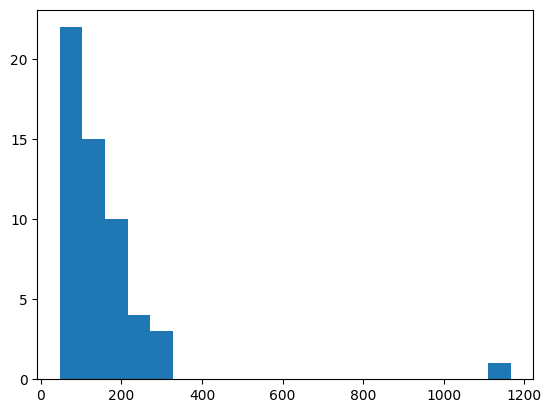

In [ ]:
plt.hist(ak4_energy, bins = 20)

error can be ignored

In [ ]:
jet_df.insert(loc=0, column = 'e_ratio', value=energy_ratio)

In [ ]:
jet_df

,e_ratio,entry,subentry,event,run,ak4_pt,ak4_eta,ak4_phi,ak4_mass,ak1_pt,ak1_eta,ak1_phi,ak1_mass,btagDeepFlavB,deepCSV_probb,deepCSV_probbb,deepCSV_probc
362,0.498929,42,0,521673324,281976,72.682693,-0.385794,2.002483,15.044004,37.843716,-0.310219,1.953685,1.600941,0.003872,0.025657,0.000760,9.572881e-02
454,0.791156,52,0,523225600,281976,67.145432,-0.634662,0.962378,8.785727,53.936913,-0.616247,0.977264,2.635731,0.002138,0.021765,0.000328,9.386547e-02
570,0.692813,66,0,522947047,281976,84.892960,-1.960250,2.733319,9.774922,58.230965,-1.971090,2.725086,2.363806,0.007517,0.099091,0.003071,1.374005e-01
713,0.517984,80,0,522660488,281976,190.178711,0.605624,-3.006094,27.540895,100.741562,0.575545,-2.966124,5.026573,0.003377,0.017986,0.000779,6.921691e-02
714,0.318532,80,1,522660488,281976,180.527069,1.005965,0.248893,14.673553,57.598351,1.005392,0.244560,1.623364,0.877751,0.961702,0.033711,4.572843e-03
797,0.729425,89,0,522113024,281976,133.020187,0.076666,-2.163131,16.822529,97.846169,0.057089,-2.166706,3.921953,0.007750,0.060366,0.001213,1.521302e-01
798,0.411279,89,1,522113024,281976,91.022446,-1.460848,0.950439,15.368663,36.876057,-1.480445,0.877593,1.635932,0.504006,0.561223,0.147247,2.484068e-01
1016,0.584048,113,0,522462723,281976,65.939919,0.000878,-0.299264,13.353459,35.917747,-0.428297,2.760698,1.562419,0.013805,0.072044,0.002814,1.065527e-01
1086,0.397751,121,0,522715589,281976,98.527939,1.265640,2.136599,17.133097,38.129795,1.301926,2.099509,2.160758,0.008071,0.034555,0.000640,9.251002e-02
1246,0.594198,141,0,522176742,281976,46.054676,-0.155058,-0.191495,8.663557,27.962137,-0.108991,-0.208084,1.523668,0.003076,0.053188,0.000678,1.509936e-01


(array([0., 0., 0., 2., 1., 7., 4., 7., 7., 3., 5., 8., 2., 8., 1., 0., 0.,
        0., 0., 0.]),
 array([0.   , 0.055, 0.11 , 0.165, 0.22 , 0.275, 0.33 , 0.385, 0.44 ,
        0.495, 0.55 , 0.605, 0.66 , 0.715, 0.77 , 0.825, 0.88 , 0.935,
        0.99 , 1.045, 1.1  ]),
 <BarContainer object of 20 artists>)

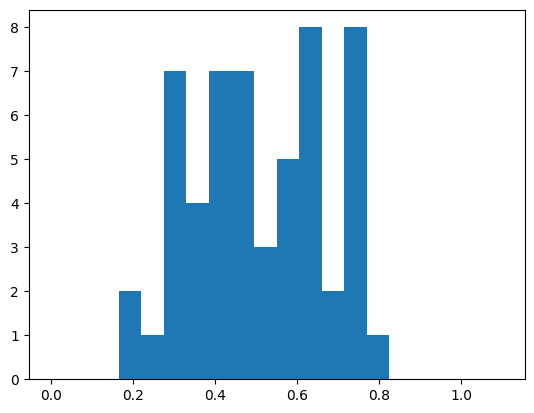

In [ ]:
plt.hist(jet_df.e_ratio,bins=20, range=(0,1.1))

In [ ]:
e_df = jet_df.loc[jet_df.e_ratio>0.75]

In [ ]:
e_df

,e_ratio,entry,subentry,event,run,ak4_pt,ak4_eta,ak4_phi,ak4_mass,ak1_pt,ak1_eta,ak1_phi,ak1_mass,btagDeepFlavB,deepCSV_probb,deepCSV_probbb,deepCSV_probc
454,0.791156,52,0,523225600,281976,67.145432,-0.634662,0.962378,8.785727,53.936913,-0.616247,0.977264,2.635731,0.002138,0.021765,0.000328,0.093865
1296,0.766208,146,0,521797724,281976,74.681786,0.211472,-0.875599,9.621682,57.973068,0.180757,-0.883307,2.327439,0.004905,0.024571,0.000262,0.095399
4586,0.756274,527,0,522085154,281976,172.315475,0.217581,0.091964,18.167961,130.952011,0.217546,0.081611,3.922527,0.004152,0.041813,0.001541,0.113303
8252,0.762745,930,0,522097650,281976,86.754677,-0.381408,2.622673,10.254433,66.987709,-0.361441,2.637895,2.963738,0.025302,0.060563,0.001287,0.136716


test muons from just the events that pass the jet filters

In [162]:
jet_pass = e_df.event
mu_pass = mu_df.loc[mu_df.event.isin(jet_pass)]
mu_pass

event     run      mu_pt    mu_eta    mu_phi   mu_mass  \
entry subentry                                                               
52    0         523225600  281976  11.355369  0.661126 -2.644748  0.105658   
      1         523225600  281976   6.957202  0.593670 -2.316686  0.105700   
      2         523225600  281976   4.256203  1.333030 -2.709912  0.105700   
      3         523225600  281976   3.678452  0.662462 -1.898475  0.105658   
      4         523225600  281976   0.796055  2.153830 -1.385147  0.105700   
146   0         521797724  281976  37.264408  0.117681  2.190961  0.105700   
      1         521797724  281976   8.606223  0.280879  2.252380  0.105700   
      2         521797724  281976   0.853134  2.159408 -1.901340  0.105700   
527   0         522085154  281976  66.694061  1.058645  1.579333  0.105658   
      1         522085154  281976  14.151003  1.150502  1.684292  0.105700   
      2         522085154  281976  11.187377  1.302572  1.491158  0.105700   
      3         522085154  281976   4.764976 -0.462825 -0.976673  0.105658   
930   0         522097650  281976  18.767622 -0.494076 -1.013215  0.105658   
      1         522097650  281976  15.012843 -0.784140 -1.038937  0.105700   
      2         522097650  281976   5.259723 -0.480027 -0.602746  0.105700   

                charge  
entry subentry          
52    0              3  
      1              3  
      2             -3  
      3              3  
      4             -3  
146   0             -3  
      1              3  
      2             -3  
527   0              3  
      1              3  
      2             -3  
      3             -3  
930   0             -3  
      1             -3  
      2              3

(array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 3., 1., 0., 0.,
        0., 0., 0.]),
 array([0.   , 0.055, 0.11 , 0.165, 0.22 , 0.275, 0.33 , 0.385, 0.44 ,
        0.495, 0.55 , 0.605, 0.66 , 0.715, 0.77 , 0.825, 0.88 , 0.935,
        0.99 , 1.045, 1.1  ]),
 <BarContainer object of 20 artists>)

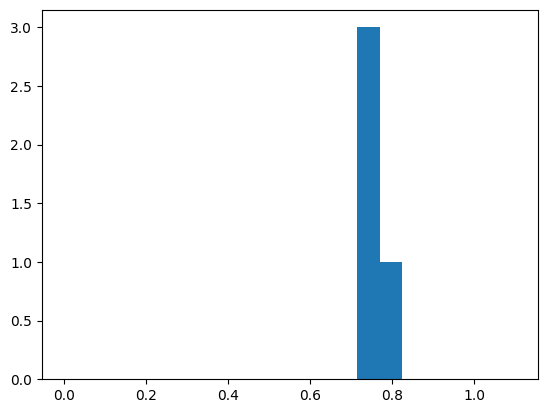

In [ ]:
plt.hist(e_df.e_ratio, bins = 20, range = (0,1.1))

(array([ 2.,  7.,  8., 12., 10.,  8.,  7.,  0.,  0.,  1.]),
 array([-1.97109008, -1.49780467, -1.02451925, -0.55123384, -0.07794843,
         0.39533699,  0.8686224 ,  1.34190781,  1.81519322,  2.28847864,
         2.76176405]),
 <BarContainer object of 10 artists>)

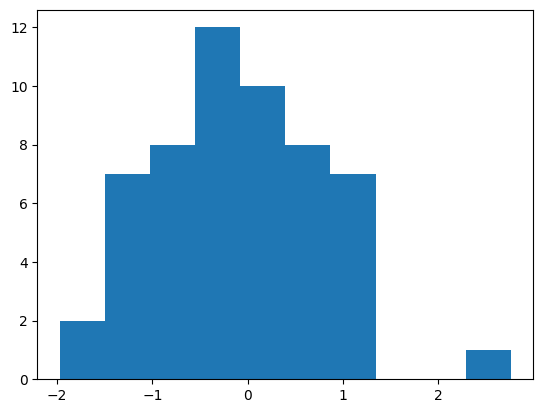

In [ ]:
plt.hist(jet_df.ak1_eta)

(array([1., 0., 0., 1., 0., 0., 0., 0., 0., 2.]),
 array([-0.61624688, -0.53286762, -0.44948836, -0.3661091 , -0.28272984,
        -0.19935058, -0.11597132, -0.03259206,  0.0507872 ,  0.13416646,
         0.21754572]),
 <BarContainer object of 10 artists>)

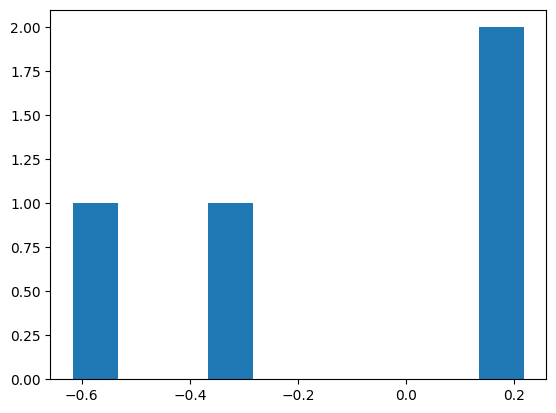

In [ ]:
plt.hist(e_df.ak1_eta)

keep energy ratio greater than 0.75
want the jet dists to match

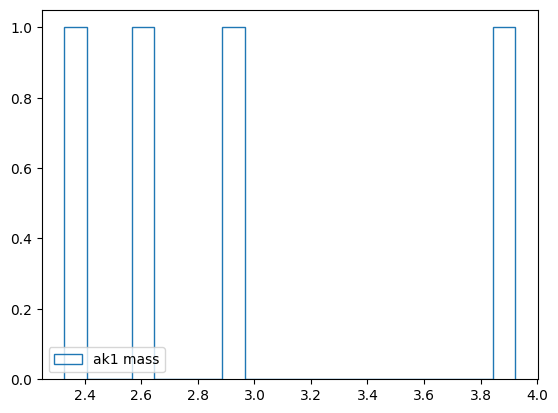

In [ ]:
plt.hist(e_df.ak1_mass, label ='ak1 mass', histtype ='step', bins = 20)
#plt.hist(e_df.ak4_mass, label = 'ak4 mass', histtype = 'step')
plt.legend()

spike around 5 is likely b jets 